# `in_hull`

Tests whether a set of coordinates lies inside a given convex hull.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.spatial import ConvexHull

import porespy as ps

ps.visualization.set_mpl_style()

## `points` and `hull`

Generate a set of vertices to define a 2D `ConvexHull` and test which random query points fall inside it:

Points inside hull: 68 / 300


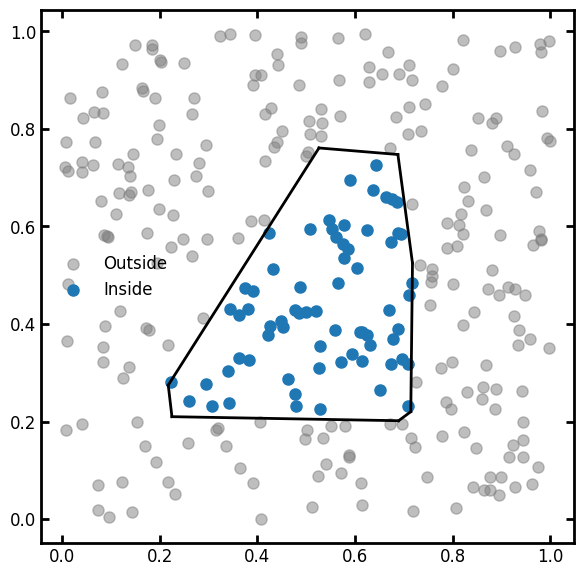

In [2]:
rng = np.random.default_rng(0)
vertices = rng.uniform(0.2, 0.8, size=(12, 2))
hull = ConvexHull(vertices)

points = rng.uniform(0.0, 1.0, size=(300, 2))
inside = ps.tools.in_hull(points=points, hull=hull)
print(f"Points inside hull: {inside.sum()} / {len(points)}")

fig, ax = plt.subplots(figsize=[6, 6])
ax.scatter(points[~inside, 0], points[~inside, 1], c="tab:gray", alpha=0.5, label="Outside")
ax.scatter(points[inside, 0], points[inside, 1], c="tab:blue", label="Inside")
for simplex in hull.simplices:
    ax.plot(vertices[simplex, 0], vertices[simplex, 1], "k-", lw=2)
ax.set_aspect("equal")
ax.legend();

You can also pass the array of hull vertex coordinates directly instead of a `ConvexHull` object:

In [3]:
inside_from_coords = ps.tools.in_hull(points=points, hull=vertices)
assert np.array_equal(inside, inside_from_coords)
print("Passing vertex coordinates directly gives identical results.")

Passing vertex coordinates directly gives identical results.
